In [1]:
import warnings; warnings.filterwarnings("ignore")
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
from credit_risk import config as C, data as D, features as F, scorecard as S, models as M
from credit_risk import calibration as CAL, business as B, fairness as FAIR, stability as ST
R = lambda s: json.load(open(C.REPORTS / f"metrics_{s}.json"))
def app():
    t = pd.read_parquet(C.ROOT / "data/synthetic/application_train.parquet")  # use data/raw + D.read_table for real data
    return F.engineer_application(D.clean_application(t)), t


# 01 - EDA and data audit
Target rate, missingness, sentinels. *Synthetic stand-in data unless you switched to the real files.*

In [2]:
df, raw = app()
audit = D.audit_application(raw)
print({k: audit[k] for k in ['rows','target_rate','imbalance_ratio','sentinel_days_employed','xna_counts']})

{'rows': 20000, 'target_rate': 0.0817, 'imbalance_ratio': 11.239902080783354, 'sentinel_days_employed': 3684, 'xna_counts': {'CODE_GENDER': 22, 'ORGANIZATION_TYPE': 3684, 'NAME_FAMILY_STATUS': 0, 'NAME_INCOME_TYPE': 0}}


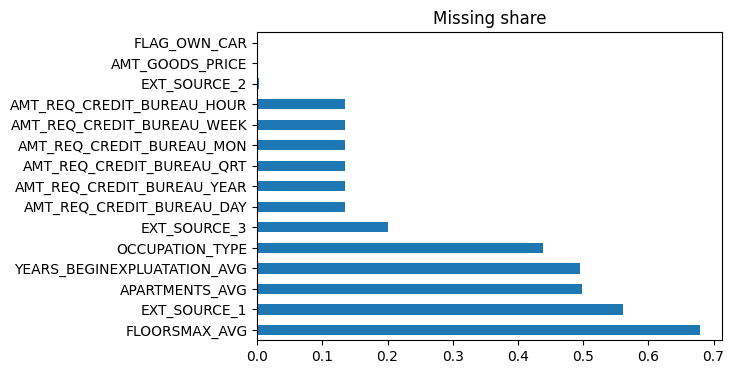

In [3]:
raw.isna().mean().sort_values(ascending=False).head(15).plot.barh(figsize=(6,4)); plt.title('Missing share'); plt.show()

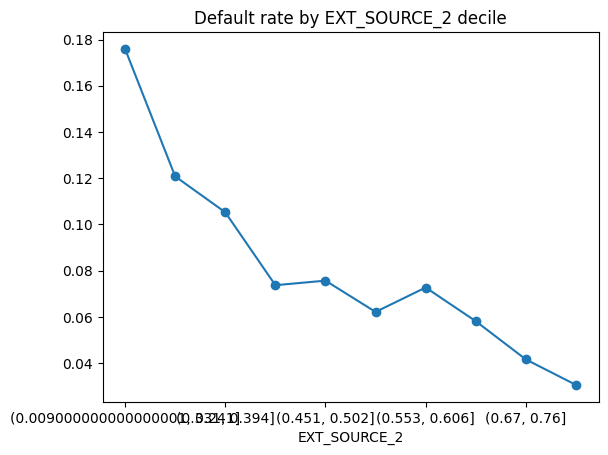

In [4]:
df.groupby(pd.qcut(df['EXT_SOURCE_2'], 10))[C.TARGET].mean().plot(marker='o'); plt.title('Default rate by EXT_SOURCE_2 decile'); plt.show()

**Takeaways:** ~8% positives (use PR-AUC, not accuracy); missing external scores are informative; `DAYS_EMPLOYED` sentinel must be neutralised.